In [7]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

DATA_DIR = ROOT / "data" / "raw"
OUTPUT_DIR = ROOT / "data" / "processed"
PLOT_DIR = ROOT / "visualizations" / "plots"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", ROOT)
print("Dataset exists:", DATA_DIR.exists())


Project root: C:\Users\S SHREYAS KUMAR\Downloads\ML_HACKATHON\PathSnap
Dataset exists: True


In [9]:

network_records = []

for partition in ["train", "student_test"]:

    partition_dir = DATA_DIR / partition

    for trip_dir in sorted(partition_dir.iterdir()):

        if not trip_dir.is_dir():
            continue

        trip_id = trip_dir.name

        # Load road nodes
        nodes = pd.read_csv(
            trip_dir / f"{trip_id}.nodes",
            sep=r"\s+",
            header=None,
            names=["longitude", "latitude"]
        )

        # Load road arcs
        arcs = pd.read_csv(
            trip_dir / f"{trip_id}.arcs",
            sep=r"\s+",
            header=None,
            names=["from_node", "to_node"]
        )

        n = len(nodes)

        # Validate node coordinates
        coordinate_valid = (
            nodes["longitude"].between(-180, 180)
            & nodes["latitude"].between(-90, 90)
            & nodes.notna().all(axis=1)
        )

        invalid_coordinates = int((~coordinate_valid).sum())

        # Validate arc endpoints
        arc_numeric = arcs.apply(pd.to_numeric, errors="coerce")

        integer_ids = (
            arc_numeric.notna().all(axis=1)
            & (arc_numeric % 1 == 0).all(axis=1)
        )

        valid_ids = (
            arc_numeric["from_node"].between(0, n - 1)
            & arc_numeric["to_node"].between(0, n - 1)
        )

        valid_mask = integer_ids & valid_ids

        valid_arcs = arc_numeric.loc[valid_mask].astype(int)

        invalid_arcs = int((~valid_mask).sum())
        duplicate_arcs = int(valid_arcs.duplicated().sum())

        # Preserve directed arc information separately
        from_ids = valid_arcs["from_node"].to_numpy()
        to_ids = valid_arcs["to_node"].to_numpy()

        # Build an undirected graph for connectivity analysis
        G = nx.Graph()

        G.add_nodes_from(range(n))

        G.add_edges_from(zip(from_ids, to_ids))

        # Calculate node degrees
        degrees = dict(G.degree())

        degree_values = np.array(list(degrees.values()))

        isolated_nodes = sum(
            1 for degree in degree_values if degree == 0
        )

        # Connected components
        components = list(nx.connected_components(G))

        component_count = len(components)

        largest_component = (
            max(len(component) for component in components)
            if components else 0
        )

        largest_component_percent = (
            largest_component / n * 100 if n else 0
        )

        # Store results
        network_records.append({

            "partition": partition,
            "trip_id": trip_id,

            "nodes": n,
            "arcs": len(arcs),
            "valid_arcs": len(valid_arcs),

            "invalid_arcs": invalid_arcs,
            "duplicate_arcs": duplicate_arcs,

            "invalid_node_coordinates": invalid_coordinates,

            "isolated_nodes": isolated_nodes,

            "connected_components": component_count,

            "largest_component_nodes": largest_component,

            "largest_component_percent": largest_component_percent,

            "average_degree": (
                degree_values.mean() if n else 0
            ),

            "maximum_degree": (
                degree_values.max() if n else 0
            )
        })

        print(
            f"Completed {partition} trip {trip_id}"
        )

# Convert results into DataFrame
network_summary = pd.DataFrame(network_records)

# Save results
network_summary.to_csv(
    OUTPUT_DIR / "road_network_quality.csv",
    index=False
)

print("\nRoad-network analysis completed.")
print("Total trips analysed:", len(network_summary))

Completed train trip 00000001
Completed train trip 00000002
Completed train trip 00000003
Completed train trip 00000004
Completed train trip 00000005
Completed train trip 00000006
Completed train trip 00000008
Completed train trip 00000010
Completed train trip 00000011
Completed train trip 00000012
Completed train trip 00000013
Completed train trip 00000014
Completed train trip 00000016
Completed train trip 00000018
Completed train trip 00000019
Completed train trip 00000020
Completed train trip 00000021
Completed train trip 00000022
Completed train trip 00000024
Completed train trip 00000025
Completed train trip 00000026
Completed train trip 00000027
Completed train trip 00000028
Completed train trip 00000029
Completed train trip 00000031
Completed train trip 00000032
Completed train trip 00000033
Completed train trip 00000034
Completed train trip 00000035
Completed train trip 00000036
Completed train trip 00000037
Completed train trip 00000038
Completed train trip 00000039
Completed 

In [12]:
summary = network_summary.groupby("partition").agg(

    total_nodes=("nodes", "sum"),

    total_arcs=("arcs", "sum"),

    valid_arcs=("valid_arcs", "sum"),

    invalid_arcs=("invalid_arcs", "sum"),

    duplicate_arcs=("duplicate_arcs", "sum"),

    isolated_nodes=("isolated_nodes", "sum"),

    connected_components=("connected_components", "sum"),

    median_largest_component_pct=(
        "largest_component_percent", "median"
    ),

    median_average_degree=("average_degree", "median")

)

display(summary)

,total_nodes,total_arcs,valid_arcs,invalid_arcs,duplicate_arcs,isolated_nodes,connected_components,median_largest_component_pct,median_average_degree
partition,,,,,,,,,
student_test,90689,185041,185041,0,128,0,227,97.060523,2.166454
train,1933485,3876904,3876904,0,1775,0,3121,98.106607,2.153858


In [14]:
summary = network_summary.groupby("partition").agg(

    total_nodes=("nodes", "sum"),

    total_arcs=("arcs", "sum"),

    valid_arcs=("valid_arcs", "sum"),

    invalid_arcs=("invalid_arcs", "sum"),

    duplicate_arcs=("duplicate_arcs", "sum"),

    isolated_nodes=("isolated_nodes", "sum"),

    connected_components=("connected_components", "sum"),

    median_largest_component_pct=(
        "largest_component_percent", "median"
    ),

    median_average_degree=("average_degree", "median")

)

display(summary)

,total_nodes,total_arcs,valid_arcs,invalid_arcs,duplicate_arcs,isolated_nodes,connected_components,median_largest_component_pct,median_average_degree
partition,,,,,,,,,
student_test,90689,185041,185041,0,128,0,227,97.060523,2.166454
train,1933485,3876904,3876904,0,1775,0,3121,98.106607,2.153858


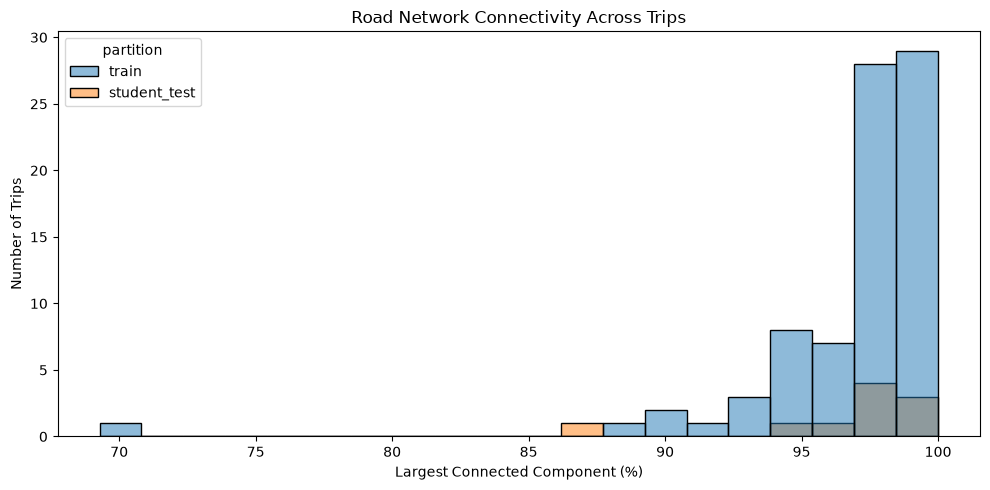

In [16]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=network_summary,
    x="largest_component_percent",
    hue="partition",
    bins=20
)

plt.title("Road Network Connectivity Across Trips")
plt.xlabel("Largest Connected Component (%)")
plt.ylabel("Number of Trips")

plt.tight_layout()

plt.savefig(
    PLOT_DIR / "road_network_connectivity.png",
    dpi=300
)

plt.show()

In [17]:
print("TOP 10 TRIPS BY ISOLATED NODES")

display(
    network_summary.nlargest(
        10, "isolated_nodes"
    )[
        [
            "partition",
            "trip_id",
            "nodes",
            "arcs",
            "isolated_nodes",
            "connected_components"
        ]
    ]
)

print("\nTOP 10 TRIPS BY INVALID ARCS")

display(
    network_summary.nlargest(
        10, "invalid_arcs"
    )[
        [
            "partition",
            "trip_id",
            "nodes",
            "arcs",
            "invalid_arcs",
            "duplicate_arcs"
        ]
    ]
)

TOP 10 TRIPS BY ISOLATED NODES


,partition,trip_id,nodes,arcs,isolated_nodes,connected_components
0,train,00000001,88809,165790,0,175
1,train,00000002,7936,16139,0,14
2,train,00000003,9138,18028,0,42
3,train,00000004,7350,15499,0,12
4,train,00000005,898,1579,0,3
5,train,00000006,3259,6757,0,8
6,train,00000008,4995,10421,0,13
7,train,00000010,8502,15715,0,28
8,train,00000011,2649,5393,0,2
9,train,00000012,16376,38599,0,22



TOP 10 TRIPS BY INVALID ARCS


,partition,trip_id,nodes,arcs,invalid_arcs,duplicate_arcs
0,train,00000001,88809,165790,0,292
1,train,00000002,7936,16139,0,0
2,train,00000003,9138,18028,0,6
3,train,00000004,7350,15499,0,5
4,train,00000005,898,1579,0,0
5,train,00000006,3259,6757,0,0
6,train,00000008,4995,10421,0,12
7,train,00000010,8502,15715,0,7
8,train,00000011,2649,5393,0,0
9,train,00000012,16376,38599,0,0
